# 05 – Farben zuordnen und mischen

**Was:** Jedem der sechs gestreckten Filterbilder einen Farbton geben und die Bilder additiv zu einem Farbbild mischen. Drei Varianten im Vergleich:

| Variante | Idee | Einordnung |
|---|---|---|
| A – chromatisch | Farbton nach Wellenlänge: kürzeste = blau, längste = rot, gleichmäßig verteilt | „wissenschaftlich“ (Reihenfolge erhalten) |
| B – NASA-Referenz | Zuordnung des offiziellen Bildes | Vergleich |
| C – physikalisch gruppiert | ionisiertes Gas, molekularer Wasserstoff und Sterne/Kontinuum je in einer Farbfamilie | frei gewählt, betont die Schichtung aus Etappe 3 |

**Warum mehr als drei Filter?** Ein Bildschirm hat nur R, G, B. Mit sechs Filtern geben wir jedem Filter einen *Farbton* (der selbst eine Mischung aus R, G, B ist) und addieren. Mikroskopie-Analogie: sechs Kanäle mit LUTs (z. B. Cyan, Magenta, Gelb …) in Fiji als *Composite* überlagern.

**Ergebnis:** Drei Farbvarianten aus denselben sechs gestreckten Filtern: A (chromatisch), B (NASA-Farbschlüssel), C (physikalisch gruppiert). Gewählt: **C**. Vorschauen in `output/previews/`, Zuordnungen in `params/ngc3132_color.json`.

In [1]:
from pathlib import Path
import json, colorsys
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.patches import Patch
from astropy.io import fits
from skimage.transform import downscale_local_mean

IN_DIR = Path("..") / "data" / "ngc3132_nircam_stretched"
OUT_DIR = Path("..") / "data" / "ngc3132_nircam_color"            # full-res, not in git
PREV_DIR = Path("..") / "output" / "previews"                     # small PNGs, in git
PARAM_FILE = Path("..") / "params" / "ngc3132_color.json"
for d in (OUT_DIR, PREV_DIR):
    d.mkdir(parents=True, exist_ok=True)

BANDS = ["F090W", "F187N", "F212N", "F356W", "F405N", "F470N"]   # sorted by wavelength
imgs = {b: fits.getdata(IN_DIR / f"ngc3132_{b.lower()}_stretched.fits").astype(np.float32) for b in BANDS}
print({b: imgs[b].shape for b in BANDS})

{'F090W': (3127, 3121), 'F187N': (3127, 3121), 'F212N': (3127, 3121), 'F356W': (3127, 3121), 'F405N': (3127, 3121), 'F470N': (3127, 3121)}


## 1. Farbe als Farbton (Hue)

Ein Farbton wird über den Winkel auf dem Farbkreis angegeben: 0° rot, 60° gelb, 120° grün, 180° cyan, 240° blau, 300° magenta. Mit voller Sättigung und Helligkeit wird daraus ein RGB-Tripel.

**Mischregel:** Für jeden Pixel `RGB = Σ (Gewicht · Filterwert · Farbe) / Σ (Gewicht · Farbe)` pro Kanal. Der Nenner sorgt dafür, dass ein Pixel, der in *allen* Filtern 1 ist, genau weiß wird; ohne ihn würde schon bei mittleren Werten viel ausbrennen. Die Gewichte erlauben, einzelne Filter etwas zu betonen oder zurückzunehmen.

In [2]:
def hue(deg):
    return np.array(colorsys.hsv_to_rgb((deg % 360) / 360, 1.0, 1.0), dtype=np.float32)

def compose(mapping, weights=None):
    """mapping: band -> RGB colour (0–1); weights: band -> factor (default 1)."""
    weights = weights or {}
    num = np.zeros(imgs[BANDS[0]].shape + (3,), np.float32)
    den = np.zeros(3, np.float32)
    for b, col in mapping.items():
        w = weights.get(b, 1.0)
        num += w * imgs[b][..., None] * col
        den += w * col
    return np.clip(num / np.maximum(den, 1e-6), 0, 1)

def show(rgb, mapping, title, ax):
    ax.imshow(rgb, origin="lower")
    ax.set_title(title)
    ax.axis("off")
    ax.legend(handles=[Patch(color=mapping[b], label=b) for b in BANDS],
              loc="lower right", fontsize=8, framealpha=0.6)

## 2. Die drei Zuordnungen

- **A – chromatisch:** Die sechs Filter in Wellenlängen-Reihenfolge, gleichmäßig von 240° (blau) bis 0° (rot) verteilt. Das ist die neutralste Wahl: Farbe ↔ Wellenlänge, nur ins Sichtbare verschoben.
- **B – NASA:** Rot F470N, Rot F405N, Gelb F356W, Grün F212N, Cyan F187N, Blau F090W (siehe PLAN.md).
- **C – physikalisch gruppiert:** Soweit ich es verstehe, zeigen F187N und F405N Wasserstoff-Rekombinationslinien (ionisiertes Gas), F212N und F470N molekularen Wasserstoff (H₂). F090W und F356W sind Breitbandfilter mit Sternen und Kontinuum. Idee: ionisiert → Blau/Cyan, molekular → Orange/Rot, breitbandig → Gelb/Weißlich. Bitte die Linien-Zuordnung bei Interesse in der JWST-Dokumentation zu den NIRCam-Filtern nachprüfen.

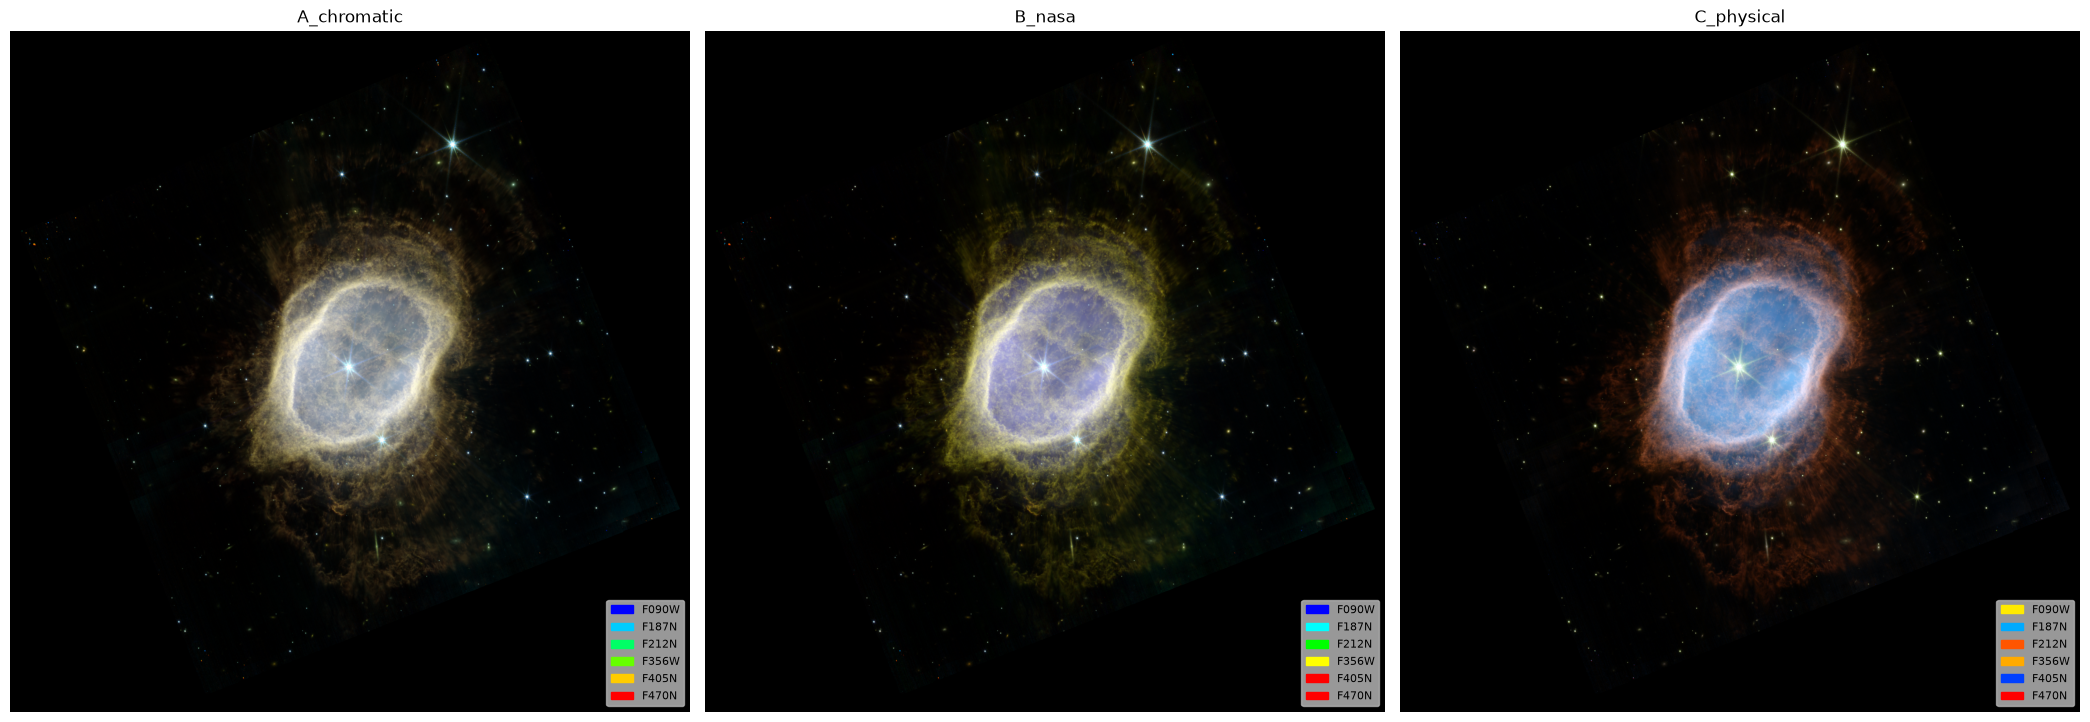

In [3]:
n = len(BANDS)
MAPPINGS = {
    "A_chromatic": {b: hue(240 - i * 240 / (n - 1)) for i, b in enumerate(BANDS)},
    "B_nasa": {"F090W": hue(240), "F187N": hue(180), "F212N": hue(120),
               "F356W": hue(60),  "F405N": hue(0),   "F470N": hue(0)},
    "C_physical": {"F090W": hue(55),  "F356W": hue(40),    # broadband: stars, continuum
                   "F187N": hue(200), "F405N": hue(225),   # ionised hydrogen
                   "F212N": hue(20),  "F470N": hue(0)},    # molecular hydrogen
}
WEIGHTS = {name: {} for name in MAPPINGS}   # all 1.0 to start

rgbs = {name: compose(m, WEIGHTS[name]) for name, m in MAPPINGS.items()}

fig, axes = plt.subplots(1, 3, figsize=(21, 7.5))
for ax, (name, m) in zip(axes, MAPPINGS.items()):
    show(rgbs[name], m, name, ax)
plt.tight_layout()

## 3. Ausschnitt: Ring und Filamente

Die Gesamtansicht täuscht leicht; im Ausschnitt sieht man, wie die Farben die Schichtung (innere Blase vs. äußere Filamente) trennen und wie die Sterne gefärbt werden. Die Koordinaten des Ausschnitts gern anpassen.

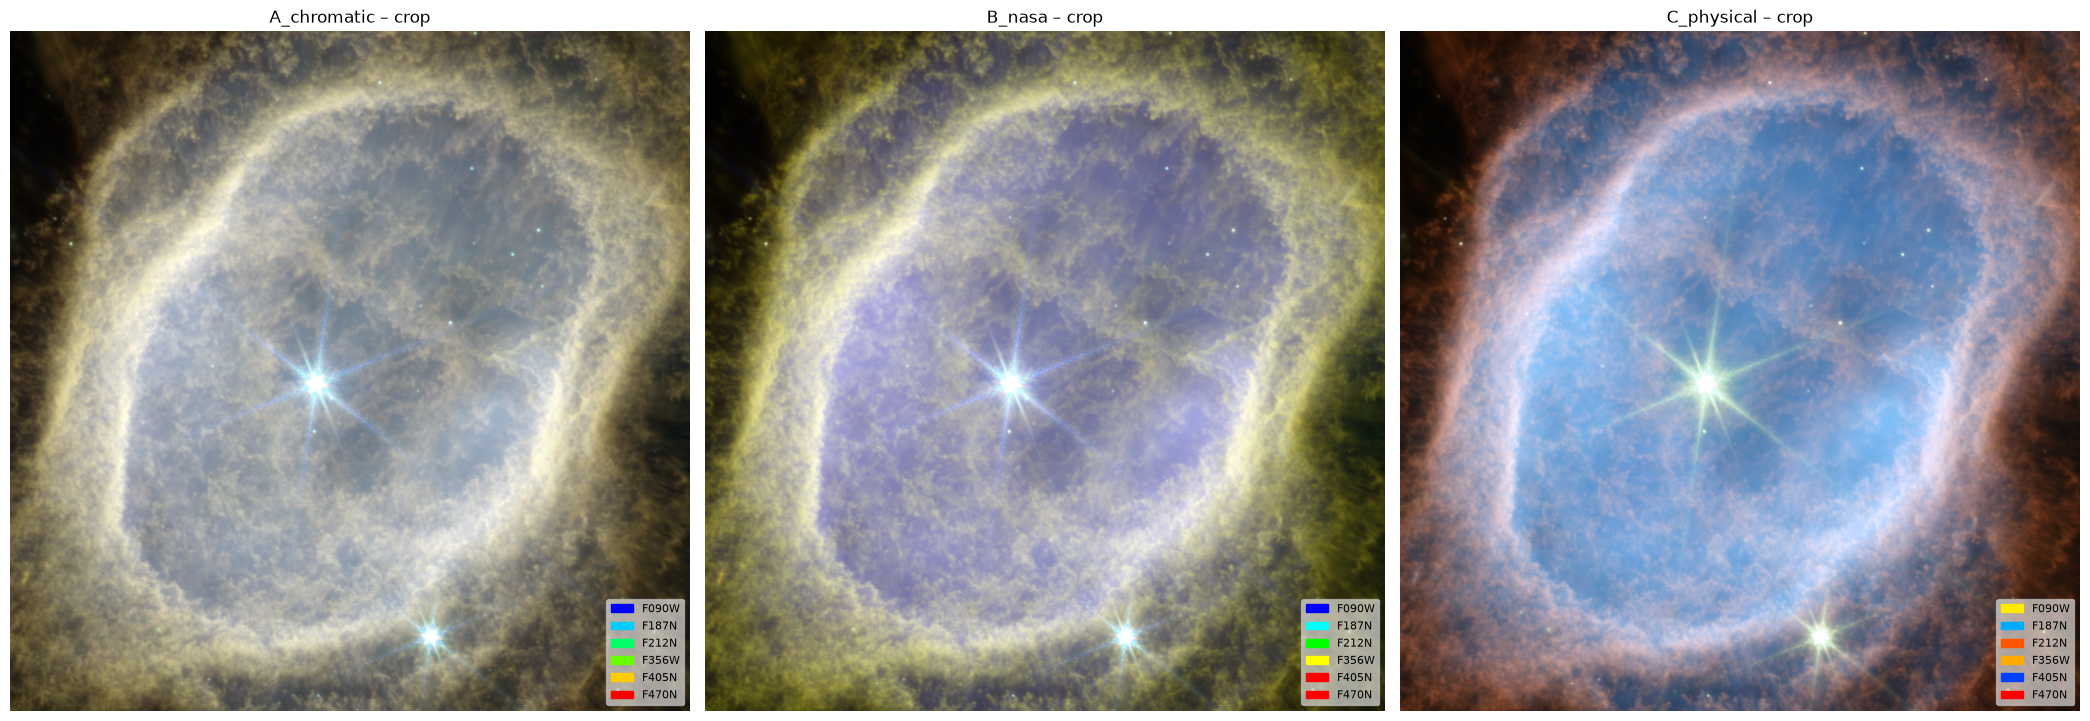

In [4]:
crop = np.s_[1150:2050, 1150:2050]   # adjust if the nebula is off-centre in your view

fig, axes = plt.subplots(1, 3, figsize=(21, 7.5))
for ax, (name, m) in zip(axes, MAPPINGS.items()):
    show(rgbs[name][crop], m, f"{name} – crop", ax)
plt.tight_layout()

## 4. Feinabstimmung (optional)

Wenn ein Filter zu dominant oder zu schwach wirkt, über `WEIGHTS` nachsteuern, z. B. `WEIGHTS["C_physical"] = {"F090W": 0.7, "F212N": 1.3}`. Gewichte verändern das Farbgleichgewicht, nicht die Struktur. Auch Farbtöne in `MAPPINGS` dürfen geändert werden; jede Änderung wird unten mitgespeichert.

**Welche Variante gefällt dir, und warum?** Das ist die eigentliche Entscheidung dieser Etappe (→ PLAN.md).

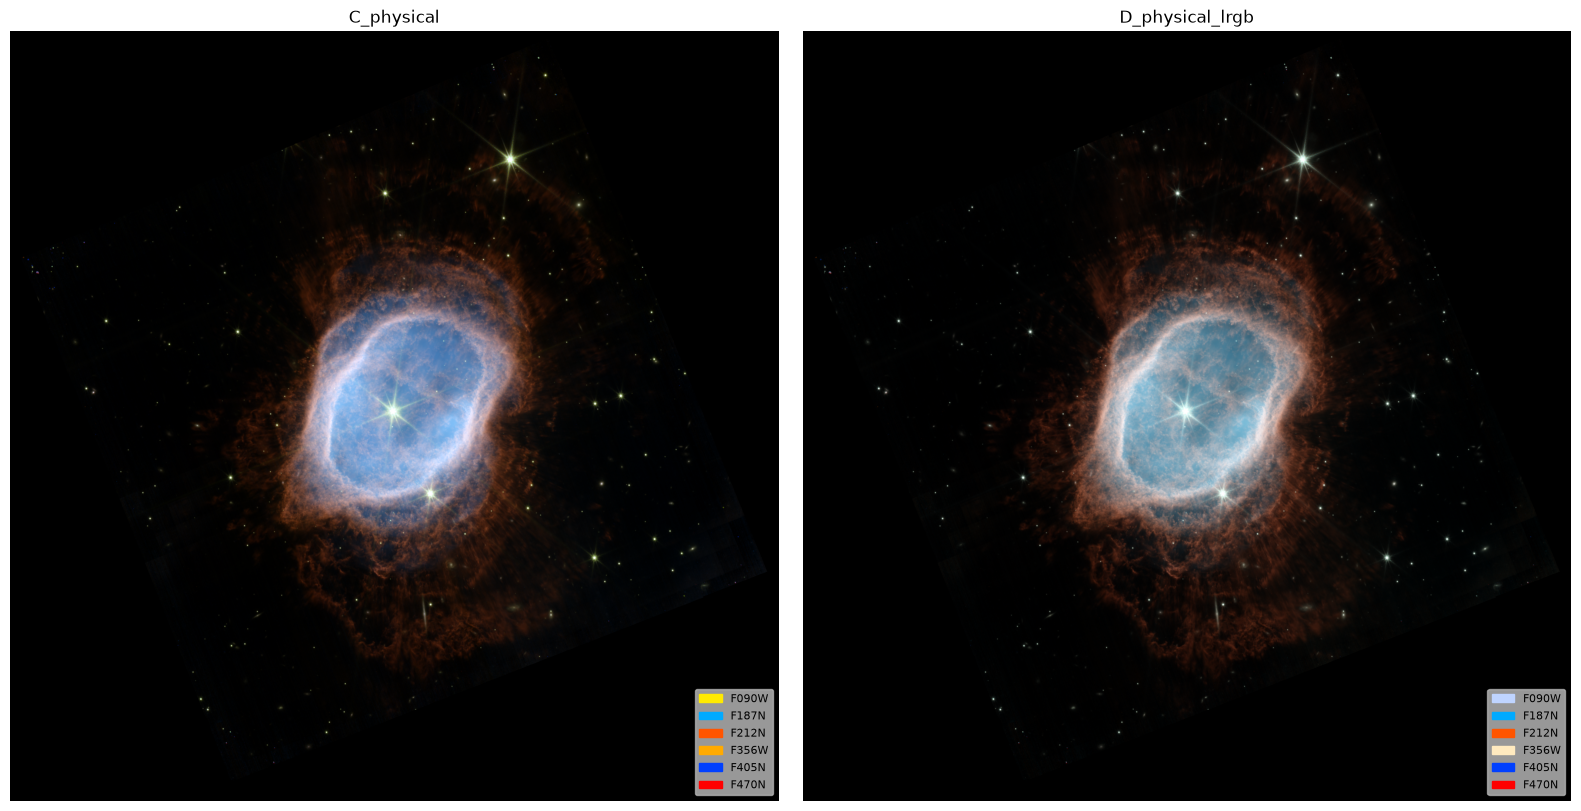

In [6]:
def hue_s(deg, s):
    """Hue with adjustable saturation (s=0 white, s=1 fully saturated)."""
    return np.array(colorsys.hsv_to_rgb((deg % 360) / 360, s, 1.0), dtype=np.float32)

# D: like C, but broadband filters only lightly tinted -> mostly luminance, white stars
MAPPINGS["D_physical_lrgb"] = {**MAPPINGS["C_physical"],
                               "F090W": hue_s(220, 0.25), "F356W": hue_s(40, 0.25)}
WEIGHTS["D_physical_lrgb"] = {}
rgbs["D_physical_lrgb"] = compose(MAPPINGS["D_physical_lrgb"])

fig, axes = plt.subplots(1, 2, figsize=(16, 8))
show(rgbs["C_physical"], MAPPINGS["C_physical"], "C_physical", axes[0])
show(rgbs["D_physical_lrgb"], MAPPINGS["D_physical_lrgb"], "D_physical_lrgb", axes[1])
plt.tight_layout()

## 5. Speichern

- Volle Auflösung als `.npy` (float32, 0–1) nach `data/ngc3132_nircam_color/` (nicht im Git) – Grundlage für den Export in Etappe 6.
- Verkleinerte Vorschau (≈ 1040 px, Mittelung über 3 × 3 Pixel) als PNG nach `output/previews/` – **kommt ins Git**, damit man im Repo sieht, wie die Varianten aussehen.
- Zuordnungen und Gewichte als JSON nach `params/ngc3132_color.json`.

In [5]:
record = {"mixing": "RGB = sum(w*img*colour) / sum(w*colour) per channel, clipped to 0-1",
          "input": str(IN_DIR), "variants": {}}
for name, m in MAPPINGS.items():
    rgb = rgbs[name]
    np.save(OUT_DIR / f"ngc3132_{name}.npy", rgb)
    small = downscale_local_mean(rgb, (3, 3, 1))
    plt.imsave(PREV_DIR / f"ngc3132_{name}_preview.png", np.clip(small, 0, 1), origin="lower")
    record["variants"][name] = {
        "colours_rgb": {b: [round(float(v), 4) for v in m[b]] for b in BANDS},
        "weights": {b: WEIGHTS[name].get(b, 1.0) for b in BANDS},
    }
    print(name, "->", OUT_DIR.name, "+", PREV_DIR / f"ngc3132_{name}_preview.png")
PARAM_FILE.write_text(json.dumps(record, indent=2))
print("parameters ->", PARAM_FILE)

A_chromatic -> ngc3132_nircam_color + ../output/previews/ngc3132_A_chromatic_preview.png
B_nasa -> ngc3132_nircam_color + ../output/previews/ngc3132_B_nasa_preview.png
C_physical -> ngc3132_nircam_color + ../output/previews/ngc3132_C_physical_preview.png
parameters -> ../params/ngc3132_color.json


## Fazit

- **A und B wirken ähnlich und eher blass** (A: gelb außen, bläulich-weiß innen; B: gelb/oliv außen, lavendel innen). Grund: Jede physikalische Komponente leuchtet in zwei weit auseinanderliegenden Filtern – molekularer Wasserstoff in F212N und F470N, ionisiertes Gas in F187N und F405N. Bei Farbe nach Wellenlänge bekommen diese Paare Gegenfarben, die sich zu entsättigten Tönen mischen.
- **C bündelt jede Komponente in einer Farbfamilie** (ionisiert → Blau/Cyan, molekular → Orange/Rot, Breitband → Gelb). Ergebnis: starker Kontrast zwischen innerer Blase und äußeren Schalen, sehr ähnlich zum veröffentlichten NASA-Bild.
- **NASA-Vergleich:** Unser B nutzt den offiziellen Farbschlüssel, sieht aber anders aus als das NASA-Bild. Der Schlüssel nennt nur Farbtöne, nicht Gewichte, Kurven oder Mischmodi – vermutlich wurde dort deutlich stärker nachbearbeitet (nicht belegt).
- **Wahrnehmung:** In C wirken Sterne und Beugungsstrahlen deutlicher, weil die Breitbandfilter (in denen Sterne am hellsten sind) gelb sind und Gelb vom Auge als hell empfunden wird; Blau (F090W in A/B) dagegen als dunkel. Die Daten sind identisch.
- **Nachteil von C:** Sterne haben einen Gelbstich. Mögliche Abhilfe (nicht umgesetzt): Breitbandfilter nur leicht tönen („LRGB“-Prinzip), sodass Sterne weiß werden.
- **Entscheidung:** Variante C für das Endbild. Ehrliche Einordnung: frei gewählt nach physikalischer Gruppierung, *nicht* chromatisch. A und B bleiben dokumentiert und sollen später per Parameter wählbar sein.

**Nächster Schritt:** Etappe 6 – Ausschnitt, Feinschliff und Export (16-bit TIFF, PNG/JPEG) mit Bildunterschrift.